In [1]:
!pip install --upgrade pip
!pip install ruptures
!pip install pytorch-lightning pytorch-forecasting
!pip install scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 18.7 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.1/823.1 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 134.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 133.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 

Mounted at /content/drive


<ipython-input-2-9e3914ba32c8>:13: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  daily = df["sentiment_intensity"].resample("D").mean().fillna(method="ffill")


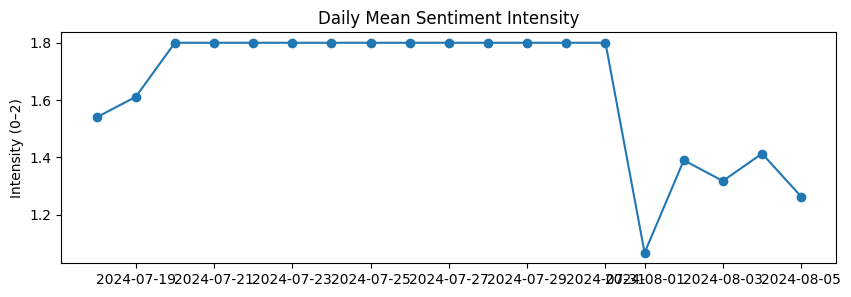

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

# Load data
df = pd.read_csv('/content/drive/MyDrive/comments_new.csv', parse_dates=["date_time"])

# 2. Build a daily series of mean intensity
df = df.set_index("date_time").sort_index()
daily = df["sentiment_intensity"].resample("D").mean().fillna(method="ffill")

# 3.Visual sanity check
plt.figure(figsize=(10,3))
plt.plot(daily.index, daily.values, marker='o')
plt.title("Daily Mean Sentiment Intensity")
plt.ylabel("Intensity (0–2)")
plt.show()


Classical ML Approach: Change-Point Detection with ruptures

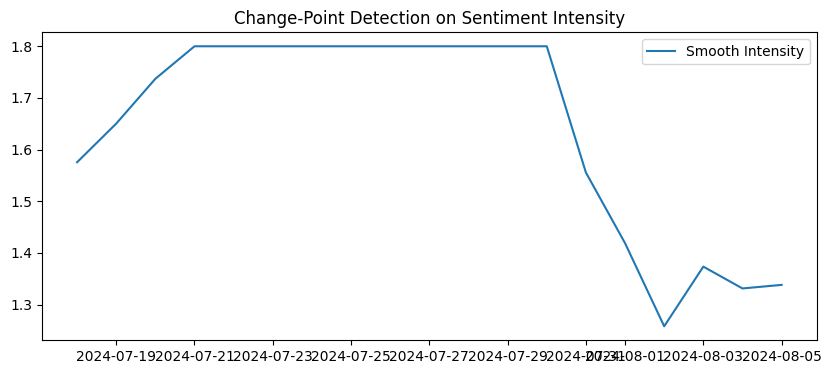

In [3]:
#Smooth the series
daily_smooth = daily.rolling(window=3, center=True, min_periods=1).mean()


#Detect change-points via the PELT algorithm
import ruptures as rpt

# fit on the smoothed values
algo = rpt.Pelt(model="rbf").fit(daily_smooth.values)
# tune penalty (pen) for sensitivity
breakpoints = algo.predict(pen=5)


plt.figure(figsize=(10,4))
plt.plot(daily_smooth.index, daily_smooth.values, label="Smooth Intensity")
for bk in breakpoints[:-1]:
    plt.axvline(daily_smooth.index[bk], color="red", linestyle="--")
plt.legend()
plt.title("Change-Point Detection on Sentiment Intensity")
plt.show()

Deep-Learning Approach: LSTM Forecast + Residual Anomaly

Epoch 1/20


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 365ms/step - loss: 0.5498 - val_loss: 0.0637
Epoch 2/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 0.5103 - val_loss: 0.0482
Epoch 3/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - loss: 0.4308 - val_loss: 0.0358
Epoch 4/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - loss: 0.3841 - val_loss: 0.0246
Epoch 5/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - loss: 0.3369 - val_loss: 0.0156
Epoch 6/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 0.3040 - val_loss: 0.0101
Epoch 7/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 0.2554 - val_loss: 0.0074
Epoch 8/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 0.2247 - val_loss: 0.0072
Epoch 9/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - loss: 0.1952 - val_loss: 0.0102
Epoch 10/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - loss: 0.1687 - val_loss: 0.0172
Epoch 11/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - loss: 0.1527 - val_loss: 0.0276
Epoch 12/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - loss: 0.1304 - val_loss: 0.0409
Epoch 13

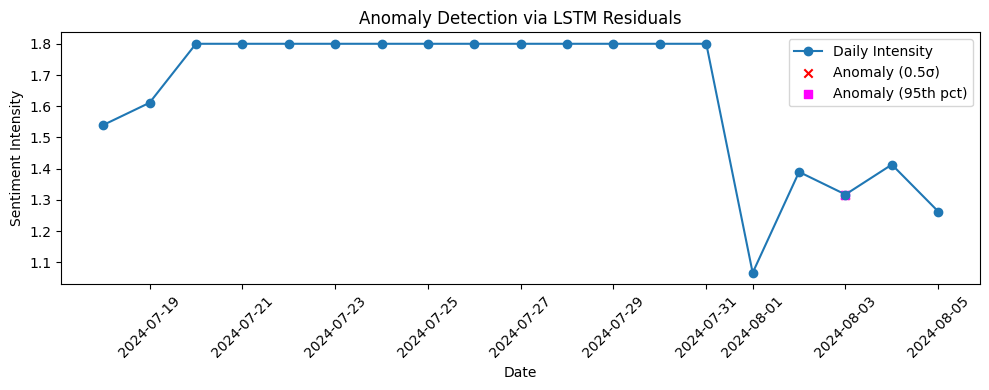

In [4]:
#Deep-Learning Approach: LSTM Forecast + Residual Anomaly
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
values = daily.values.reshape(-1,1)
scaled = scaler.fit_transform(values)


#Create windowed sequences (look-back T days → predict next day)
T = 7
X, y = [], []
for i in range(len(scaled) - T):
    X.append(scaled[i:i+T])
    y.append(scaled[i+T])
X, y = np.array(X), np.array(y)


split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]


#Define & train LSTM (TensorFlow/Keras)
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import LSTM, Dense

model = Sequential([
    LSTM(32, input_shape=(T,1)),
    Dense(1)
])
model.compile(optimizer="adam", loss="mse")
model.fit(X_train, y_train, epochs=20, batch_size=8,
          validation_data=(X_test, y_test))



# 1) Predict & compute residuals
preds = model.predict(X_test).flatten()     # shape (n_test,)
y_true = y_test.flatten()
resid = np.abs(preds - y_true)             # shape (n_test,)

# 2) Sigma‐based threshold (0.5σ)
sigma_thresh = resid.mean() + 0.5 * resid.std()
anomalies_sigma = np.where(resid > sigma_thresh)[0]

# 3) Percentile‐based threshold (95th percentile)
pct_thresh = np.percentile(resid, 95)
anomalies_pct = np.where(resid > pct_thresh)[0]

# 4) Map to the full 'daily' index
# The test window in 'daily' starts at position (split + T)
start_idx = split + T
anomaly_dates_sigma = daily.index[start_idx + anomalies_sigma]
anomaly_dates_pct   = daily.index[start_idx + anomalies_pct]

# 5) Print thresholds & counts for sanity
print(f"Sigma threshold: {sigma_thresh:.3f}, anomalies found: {len(anomalies_sigma)}")
print(f"Percentile threshold: {pct_thresh:.3f}, anomalies found: {len(anomalies_pct)}")

# 6) Plot both on the same chart
plt.figure(figsize=(10,4))
plt.plot(daily.index, daily.values, label="Daily Intensity", marker='o')
plt.scatter(anomaly_dates_sigma, daily.loc[anomaly_dates_sigma],
            color='red', marker='x', label="Anomaly (0.5σ)")
plt.scatter(anomaly_dates_pct, daily.loc[anomaly_dates_pct],
            color='magenta', marker='s', label="Anomaly (95th pct)")
plt.legend()
plt.title("Anomaly Detection via LSTM Residuals")
plt.xlabel("Date")
plt.ylabel("Sentiment Intensity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 5, 64)          │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 5, 64)          │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           321 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,929 (50.50 KB)

 Trainable params: 12,929 (50.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
1360/1360 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.8084 - mean_squared_error: 1.4376 - val_loss: 0.7134 - val_mean_squared_error: 1.2243
Epoch 2/30
1360/1360 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.8002 - mean_squared_error: 1.5714 - val_loss: 0.7012 - val_mean_squared_error: 1.3048
Epoch 3/30
1360/1360 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.7715 - mean_squared_error: 1.5661 - val_loss: 0.6985 - val_mean_squared_error: 1.3415
Epoch 4/30
1360/1360 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.7646 - mean_squared_error: 1.5710 - val_loss: 0.6996 - val_mean_squared_error: 1.3476
Epoch 5/30
1360/1360 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.7676 - mean_squared_error: 1.5782 - val_loss: 0.6986 - val_mean_squared_error: 1.3498
Epoch 6/30
1360/1360 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.7702 - mean_squared_error: 1.6106 - val_loss: 0.7015 - val_mean_squared_error: 1.3294
Epoch 7/30
1360/1360 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.7707 - mean_squared_error: 1.6165 - 

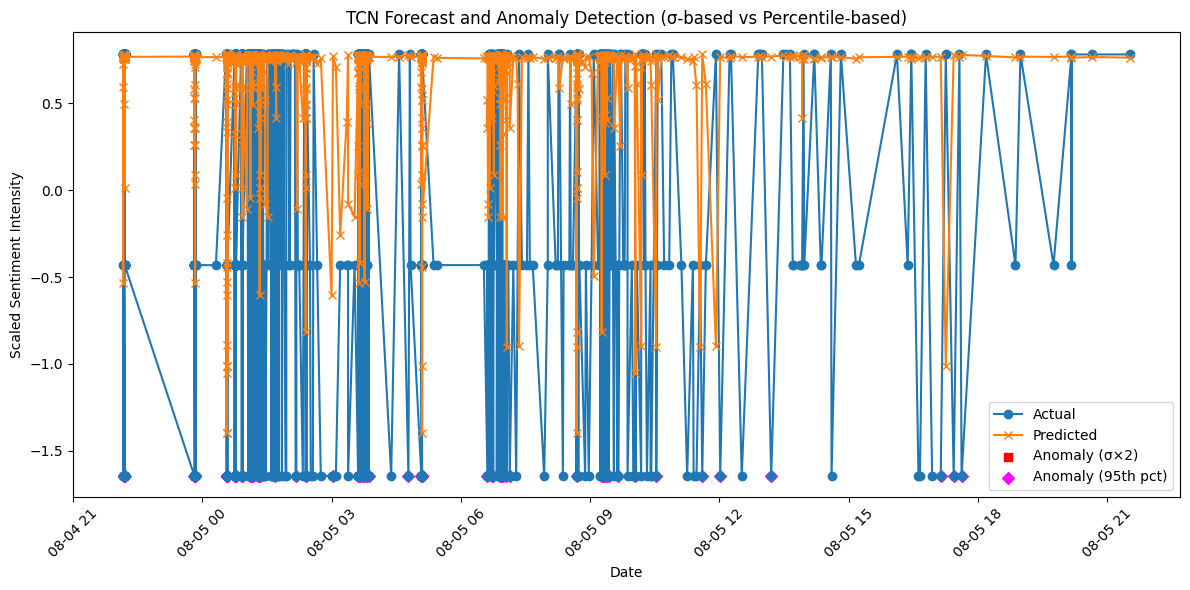

In [5]:
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Dense, Flatten, InputLayer
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import MeanAbsoluteError
from tensorflow.keras.metrics import MeanSquaredError

# Load the real dataset
df = pd.read_csv('/content/drive/MyDrive/comments_new.csv', parse_dates=['date_time'])
df = df[['date_time', 'sentiment_intensity']].dropna().sort_values('date_time')
df.set_index('date_time', inplace=True)

# Normalize the data
scaler = StandardScaler()
df['scaled'] = scaler.fit_transform(df[['sentiment_intensity']])

# Define windowing function for supervised learning
def create_dataset(series, window_size=5):
    X, y = [], []
    for i in range(len(series) - window_size):
        X.append(series[i:i+window_size])
        y.append(series[i+window_size])
    return np.array(X), np.array(y)

# Create dataset
window_size = 5
X, y = create_dataset(df['scaled'].values, window_size)
X = X[..., np.newaxis]  # shape (samples, window_size, 1)

# Train-test split
split = int(len(X) * 0.8)
X_train, y_train = X[:split], y[:split]
X_test,  y_test  = X[split:], y[split:]

# Build the TCN-like model
model = Sequential([
    InputLayer(input_shape=(window_size, 1)),
    Conv1D(64, 3, activation='relu', padding='causal'),
    Conv1D(64, 3, activation='relu', padding='causal'),
    Flatten(),
    Dense(1)
])
model.compile(optimizer=Adam(1e-3),
              loss=MeanAbsoluteError(),
              metrics=[MeanSquaredError()])
model.summary()

# Train
model.fit(X_train, y_train, epochs=30, batch_size=4,
          validation_split=0.2, verbose=1)

# Predict & compute residuals
pred = model.predict(X_test).flatten()
residuals = np.abs(pred - y_test)

# σ-based threshold (0.5σ or 2σ)
sigma_multiplier = 2
sigma_thresh = residuals.mean() + sigma_multiplier * residuals.std()
anoms_sigma = np.where(residuals > sigma_thresh)[0]

# Percentile-based threshold (95th percentile)
pct_thresh = np.percentile(residuals, 95)
anoms_pct = np.where(residuals > pct_thresh)[0]

# Map anomalies back to timestamps
pred_dates = df.index[split + window_size:]
dates_sigma = pred_dates[anoms_sigma]
dates_pct   = pred_dates[anoms_pct]

# Print counts & thresholds
print(f"σ-based (×{sigma_multiplier}) thresh: {sigma_thresh:.3f}, anomalies: {len(anoms_sigma)}")
print(f"95th percentile thresh:      {pct_thresh:.3f}, anomalies: {len(anoms_pct)}")

# Plot actual vs predicted + both anomaly sets
plt.figure(figsize=(12,6))
plt.plot(pred_dates, y_test, label='Actual', marker='o')
plt.plot(pred_dates, pred, label='Predicted', marker='x')
plt.scatter(dates_sigma, y_test[anoms_sigma],
            color='red', marker='s', label=f'Anomaly (σ×{sigma_multiplier})')
plt.scatter(dates_pct, y_test[anoms_pct],
            color='magenta', marker='D', label='Anomaly (95th pct)')
plt.title("TCN Forecast and Anomaly Detection (σ-based vs Percentile-based)")
plt.xlabel("Date")
plt.ylabel("Scaled Sentiment Intensity")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Ground-truth events marked: 4 days out of 19
ruptures     flags 0 anomalies out of 19 days
lstm_sigma   flags 1 anomalies out of 19 days
lstm_pct     flags 1 anomalies out of 19 days
tcn_sigma    flags 0 anomalies out of 19 days
tcn_pct      flags 2 anomalies out of 19 days

Evaluation of Shift Detectors vs. Event Dates:


,precision,recall,f1
method,,,
ruptures,None,None,None
lstm_sigma,0.0,0.0,0.0
lstm_pct,0.0,0.0,0.0
tcn_sigma,None,None,None
tcn_pct,0.5,0.25,0.333333


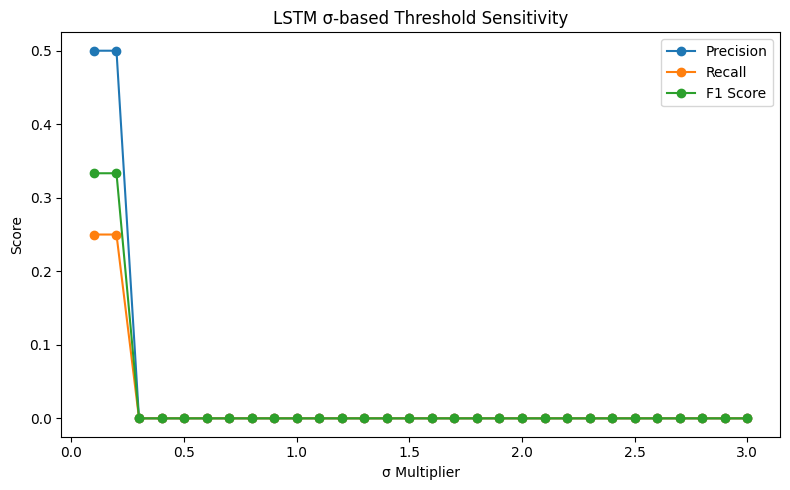

In [8]:
# 1) Ground-truth event dates (date-only matching)
event_dates = pd.to_datetime([
    "2024-07-18",  # protest start
    "2024-07-25",  # first major clash
    "2024-08-01",  # crackdown peak
    "2024-08-05",  # government resignation
]).date

daily_dates = np.array([d.date() for d in daily.index])
y_true = np.array([1 if d in event_dates else 0 for d in daily_dates])
print("Ground-truth events marked:", y_true.sum(), "days out of", len(y_true))

# 2) Prepare y_pred vectors (date-only)
def build_pred_vector_dates(anom_timestamps, all_timestamps):
    anom_dates = {ts.date() for ts in anom_timestamps}
    all_dates = [ts.date() for ts in all_timestamps]
    return np.array([1 if d in anom_dates else 0 for d in all_dates])

# A) Ruptures
cp_dates = daily.index[[bp for bp in breakpoints[:-1]]]

# B) LSTM anomalies
lst_sigma_dates = anomaly_dates_sigma
lst_pct_dates   = anomaly_dates_pct

# C) TCN anomalies
tcn_sigma_dates = dates_sigma
tcn_pct_dates   = dates_pct

daily_index = daily.index

y_pred = {
    "ruptures":   build_pred_vector_dates(cp_dates,      daily_index),
    "lstm_sigma": build_pred_vector_dates(lst_sigma_dates, daily_index),
    "lstm_pct":   build_pred_vector_dates(lst_pct_dates,   daily_index),
    "tcn_sigma":  build_pred_vector_dates(tcn_sigma_dates, daily_index),
    "tcn_pct":    build_pred_vector_dates(tcn_pct_dates,   daily_index),
}

# Sanity check: how many days each method flags?
for name, vec in y_pred.items():
    print(f"{name:12s} flags {vec.sum()} anomalies out of {len(vec)} days")

# 3) Compute Precision / Recall / F1 for each method
results = {}
for name, y_p in y_pred.items():
    if y_p.sum() == 0:
        results[name] = {"precision": None, "recall": None, "f1": None}
    else:
        results[name] = {
            "precision": precision_score(y_true, y_p, zero_division=0),
            "recall":    recall_score(y_true, y_p),
            "f1":        f1_score(y_true, y_p),
        }

eval_df = pd.DataFrame(results).T.rename_axis("method")
print("\nEvaluation of Shift Detectors vs. Event Dates:")
display(eval_df)

# 4) Threshold Sensitivity Analysis for LSTM σ-based method
thresholds = np.linspace(0.1, 3.0, 30)  # σ multiplier sweep
sens_results = []

for m in thresholds:
    thr = resid.mean() + m * resid.std()
    idxs = np.where(resid > thr)[0]
    dates_m = daily.index[start_idx + idxs]
    y_p = build_pred_vector_dates(dates_m, daily_index)
    sens_results.append({
        "multiplier": m,
        "precision": precision_score(y_true, y_p, zero_division=0),
        "recall":    recall_score(y_true, y_p),
        "f1":        f1_score(y_true, y_p),
    })

sens_df = pd.DataFrame(sens_results)

plt.figure(figsize=(8,5))
plt.plot(sens_df["multiplier"], sens_df["precision"], marker='o', label="Precision")
plt.plot(sens_df["multiplier"], sens_df["recall"],    marker='o', label="Recall")
plt.plot(sens_df["multiplier"], sens_df["f1"],        marker='o', label="F1 Score")
plt.xlabel("σ Multiplier")
plt.ylabel("Score")
plt.title("LSTM σ-based Threshold Sensitivity")
plt.legend()
plt.tight_layout()
plt.show()

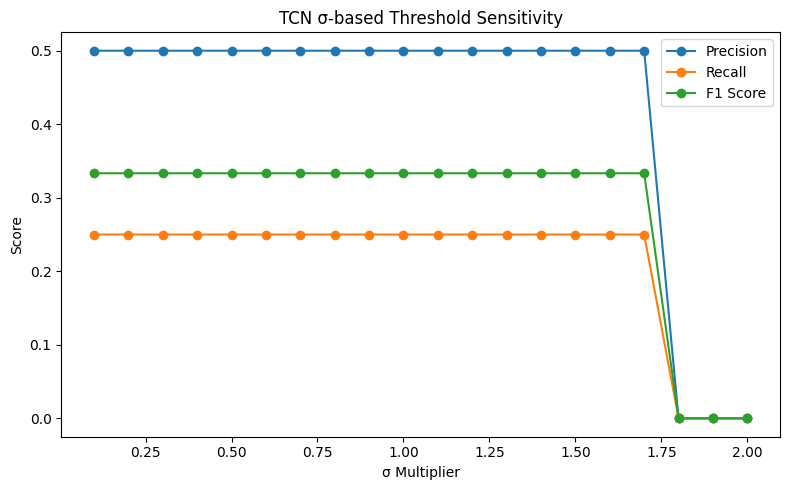

In [10]:
# ───────────── TCN σ-based Threshold Sensitivity (Fixed) ─────────────

from sklearn.metrics import precision_score, recall_score, f1_score

# multipliers to test
multipliers = np.linspace(0.1, 2.0, 20)
tcn_sens = []

# pred_dates is the array of timestamps corresponding to each residual
# defined earlier as:
#    pred_dates = df.index[split + window_size:]

for m in multipliers:
    thr = residuals.mean() + m * residuals.std()
    idxs = np.where(residuals > thr)[0]
    # Map anomaly indices into actual timestamps from pred_dates
    dates_m = pred_dates[idxs]
    # Build binary prediction over the full daily.index
    y_p = build_pred_vector_dates(dates_m, daily.index)
    tcn_sens.append({
        "multiplier": m,
        "precision": precision_score(y_true, y_p, zero_division=0),
        "recall":    recall_score(y_true, y_p),
        "f1":        f1_score(y_true, y_p),
    })

tcn_sens_df = pd.DataFrame(tcn_sens)

plt.figure(figsize=(8,5))
plt.plot(tcn_sens_df["multiplier"], tcn_sens_df["precision"], marker='o', label="Precision")
plt.plot(tcn_sens_df["multiplier"], tcn_sens_df["recall"],    marker='o', label="Recall")
plt.plot(tcn_sens_df["multiplier"], tcn_sens_df["f1"],        marker='o', label="F1 Score")
plt.xlabel("σ Multiplier")
plt.ylabel("Score")
plt.title("TCN σ-based Threshold Sensitivity")
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
# Save the settings you’ll reuse downstream
detector_config = {
    "method": "TCN_residuals",
    "sigma_multiplier": 1.8,
    "percentile": 95,
    "ensemble": ["sigma", "percentile"]
}
# Optionally write to disk for reproducibility
import json
with open("tcn_detector_config.json", "w") as f:
    json.dump(detector_config, f, indent=2)